In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

sys.path.append("../..")

import json
from pathlib import Path
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid", {"grid.color": ".93"})

from src.data_processing.load_data import ClimateModelData, ClimateReanalysisData

from src.utils.utils_load_data import (
    get_raw_cordex_data_paths,
)

from src.data_processing.convert_climate_vars import (
    convert_wind_components_to_speed,
)

In [3]:
paths = json.load(open("../../paths_so4.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])
path_data_cordex = Path(paths["path_data_cordex"])
path_data_adjusted_cordex = Path(paths["path_data_adjusted_cordex"])
path_data_cerra = Path(paths["path_data_cerra"])
path_data_cerra_land = Path(paths["path_data_cerra_land"])
path_data_personal = Path(paths["path_data_personal"])
path_data_personal_cordex = path_data_personal / "cordex"

path_energy_ch = path_data_processed / "energy" / "ch"

path_figs = Path(paths["path_figs"])

In [4]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp26"

institute = climate_model_chain.split("-")[0]
rcm = climate_model_chain.split("_")[0]
gcm = climate_model_chain.split("_")[1]
ensemble = climate_model_chain.split("_")[-1]

# Test

In [6]:
cordex_wind_100m, cordex_wind_hist_100m = get_raw_cordex_data_paths(
    Path(paths["path_data_personal"]) / "cordex" / "EUR-11",
    climate_model_chain,
    climate_scenario,
    "wind100m",
    "3hr",
)

In [42]:
cordex_wind_150m, cordex_wind_hist_150m = get_raw_cordex_data_paths(
    Path(paths["path_data_personal"]) / "cordex" / "EUR-11",
    climate_model_chain,
    climate_scenario,
    "wind150m",
    "3hr",
)

In [ ]:
ds_wind100m = xr.open_dataset(
    sorted(cordex_wind_100m.glob("*202801010300-202901010000.nc"))[0]
)
ds_wind150m = xr.open_dataset(
    sorted(cordex_wind_150m.glob("*202801010300-202901010000.nc"))[0]
)

In [21]:
ds_wind100m

<xarray.Dataset> Size: 2GB
Dimensions:            (y: 453, x: 453, nvertex: 4, time: 2928)
Coordinates:
    lat                (y, x) float64 2MB ...
    lon                (y, x) float64 2MB ...
    height             float64 8B ...
  * time               (time) datetime64[ns] 23kB 2028-01-01T03:00:00 ... 202...
  * x                  (x) float64 4kB 0.0 12.5 25.0 ... 5.638e+03 5.65e+03
  * y                  (y) float64 4kB 0.0 12.5 25.0 ... 5.638e+03 5.65e+03
Dimensions without coordinates: nvertex
Data variables:
    bounds_lon         (y, x, nvertex) float64 7MB ...
    bounds_lat         (y, x, nvertex) float64 7MB ...
    Lambert_Conformal  |S1 1B ...
    wind100m           (time, y, x) float32 2GB ...
Attributes: (12/25)
    description:                    Created by xios
    title:                          Created by xios
    Conventions:                    CF-1.6
    creation_date:                  2020-03-31T10:53:12Z
    tracking_id:                    hdl:21.14103/3dbfcf2e-87ff-4344-b4c4-8c03...
    name:                           EUR-11_CNRM-CERFACS-CNRM-CM5_rcp85_r1i1p1...
    ...                             ...
    CORDEX_domain:                  EUR-11
    references:                     http://www.umr-cnrm.fr/spip.php?article12...
    comment:                        CORDEX Europe EUR-11 CNRM-ALADIN 6.3 L91 ...
    c3s_disclaimer:                 This data has been produced in the contex...
    driving_experiment_comment:     Known issue correction: this simulation (...
    frequency:                      3hr

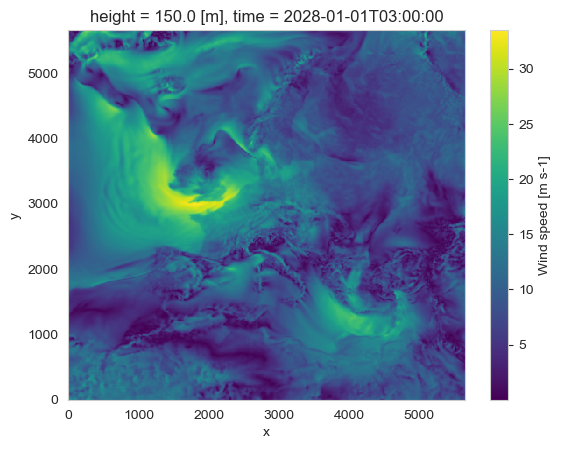

In [20]:
ds_wind150m.isel(time=0).wind150m.plot()

In [ ]:
alpha = np.log(ds_wind150m.wind150m / ds_wind100m.wind100m) / np.log(150 / 100)

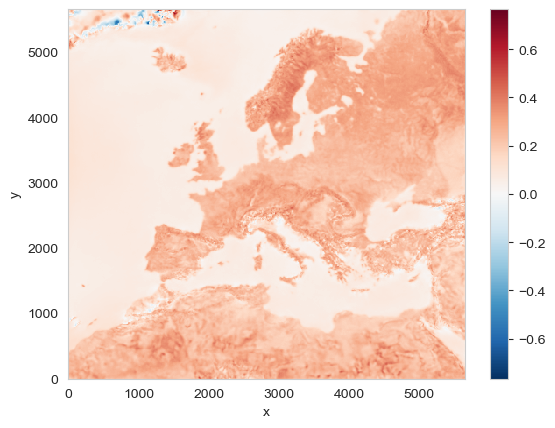

In [19]:
alpha.mean("time").plot()

In [6]:
path_data_personal_cordex = Path(paths["path_data_personal"]) / "cordex" / "EUR-11"
u_path = sorted(
    list(
        (path_data_personal_cordex / institute / gcm / climate_scenario).rglob(
            f"*/ua{100}m"
        )
    )[0].glob("*/*.nc")
)
v_path = sorted(
    list(
        (path_data_personal_cordex / institute / gcm / climate_scenario).rglob(
            f"*/va{100}m"
        )
    )[0].glob("*/*.nc")
)

In [ ]:
ds_u = xr.open_dataset(u_path[0])
ds_v = xr.open_dataset(v_path[0])

<xarray.Dataset> Size: 2GB
Dimensions:            (y: 453, x: 453, nvertex: 4, time: 2920)
Coordinates:
    lat                (y, x) float64 2MB 20.98 21.01 21.04 ... 63.73 63.65
    lon                (y, x) float64 2MB -14.31 -14.21 -14.11 ... 72.4 72.56
    height             float64 8B 150.0
  * time               (time) datetime64[ns] 23kB 2006-01-01T03:00:00 ... 200...
  * x                  (x) float64 4kB 0.0 12.5 25.0 ... 5.638e+03 5.65e+03
  * y                  (y) float64 4kB 0.0 12.5 25.0 ... 5.638e+03 5.65e+03
Dimensions without coordinates: nvertex
Data variables:
    bounds_lon         (y, x, nvertex) float64 7MB -14.35 -14.24 ... 72.74 72.57
    bounds_lat         (y, x, nvertex) float64 7MB 20.92 20.95 ... 63.65 63.72
    ua150m             (time, y, x) float32 2GB -6.12 -5.85 ... -12.79 -13.22
    Lambert_Conformal  |S1 1B b''
Attributes: (12/25)
    description:                    Created by xios
    title:                          Created by xios
    Conventions:                    CF-1.6
    creation_date:                  2020-03-20T10:44:11Z
    tracking_id:                    hdl:21.14103/61db9aeb-41d4-4c99-bade-6553...
    name:                           EUR-11_CNRM-CERFACS-CNRM-CM5_rcp85_r1i1p1...
    ...                             ...
    CORDEX_domain:                  EUR-11
    references:                     http://www.umr-cnrm.fr/spip.php?article12...
    comment:                        CORDEX Europe EUR-11 CNRM-ALADIN 6.3 L91 ...
    c3s_disclaimer:                 This data has been produced in the contex...
    driving_experiment_comment:     Known issue correction: this simulation (...
    frequency:                      3hr

In [ ]:
extent = {"lat_min": 30, "lat_max": 75, "lon_min": -12, "lon_max": 30}

ds_wind_150m = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85"
    / "regridded"
    / "3hr"
    / "wind150m.zarr",
    extent=extent,
)

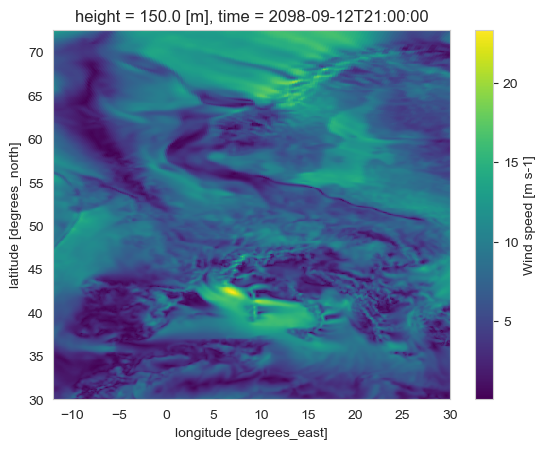

In [8]:
ds_wind_150m.ds_data.isel(time=-1).wind150m.plot()

In [9]:
extent = {"lat_min": 30, "lat_max": 75, "lon_min": -12, "lon_max": 30}

ds_wind_100m = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85"
    / "regridded"
    / "3hr"
    / "wind100m.zarr",
    extent=extent,
)

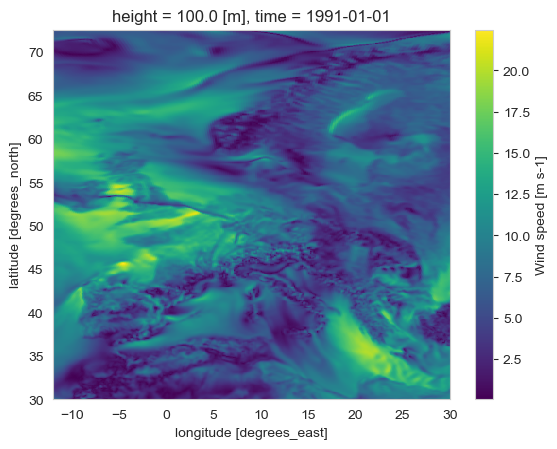

In [11]:
ds_wind_100m.ds_data.isel(time=0).wind100m.plot()

In [12]:
extent = {"lat_min": 30, "lat_max": 75, "lon_min": -12, "lon_max": 30}

ds_wind_150m = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85"
    / "regridded"
    / "3hr"
    / "wind150m.zarr",
    extent=extent,
)

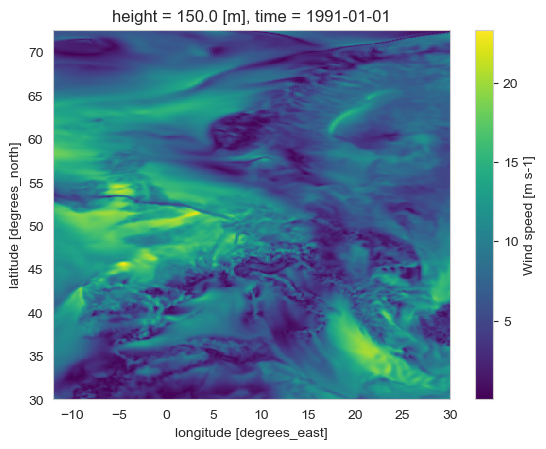

In [13]:
ds_wind_150m.ds_data.isel(time=0).wind150m.plot()

In [14]:
extent = {"lat_min": 30, "lat_max": 75, "lon_min": -12, "lon_max": 30}

ds_wind_200m = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85"
    / "regridded"
    / "3hr"
    / "wind200m.zarr",
    extent=extent,
)

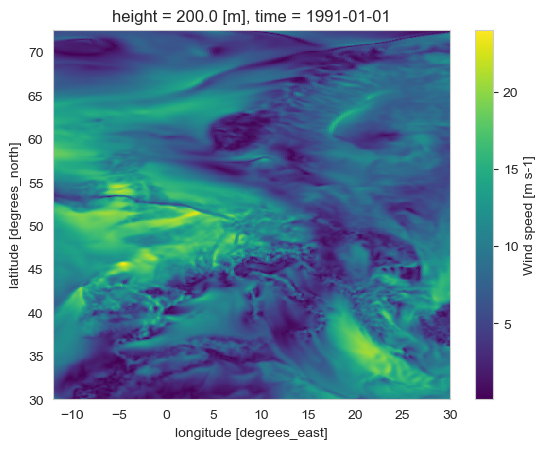

In [15]:
ds_wind_200m.ds_data.isel(time=0).wind200m.plot()

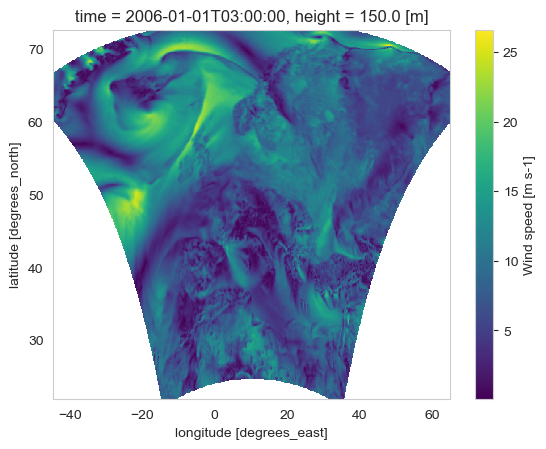

In [ ]:
wind150m_hist = Path(
    "/landclim/yhaddad/clim2energy-ch/cordex_processed/CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85/temp/wind150m/future/"
)
xr.open_dataset(sorted(wind150m_hist.glob("*.nc"))[0]).isel(time=0).wind150m.plot()

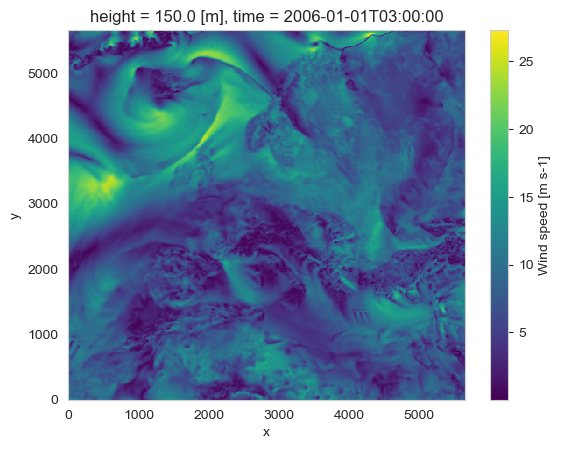

In [12]:
xr.open_dataset(sorted(cordex_wind_150m.glob("*.nc"))[0]).isel(time=0).wind150m.plot()

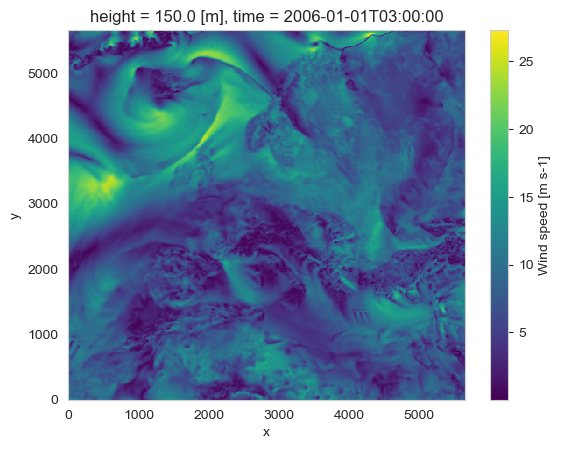

In [18]:
xr.open_dataset(sorted(cordex_wind_150m.glob("*.nc"))[0]).isel(time=0).wind150m.plot()

In [7]:
cordex_wind_150m

PosixPath('/landclim/yhaddad/cordex/EUR-11/rcp85/3hr/wind150m/CNRM/CNRM-CERFACS-CNRM-CM5/CNRM-ALADIN63/r1i1p1')

In [15]:
ds = xr.open_dataset(sorted(cordex_wind_hist_150m.glob("*.nc"))[-3])
null_time_steps = ds.wind150m.where(ds.wind150m.isnull(), drop=True)["time"]
null_time_steps

<xarray.DataArray 'time' (time: 1)> Size: 8B
array(['2003-09-13T00:00:00.000000000'], dtype='datetime64[ns]')
Coordinates:
    height   float64 8B 150.0
  * time     (time) datetime64[ns] 8B 2003-09-13

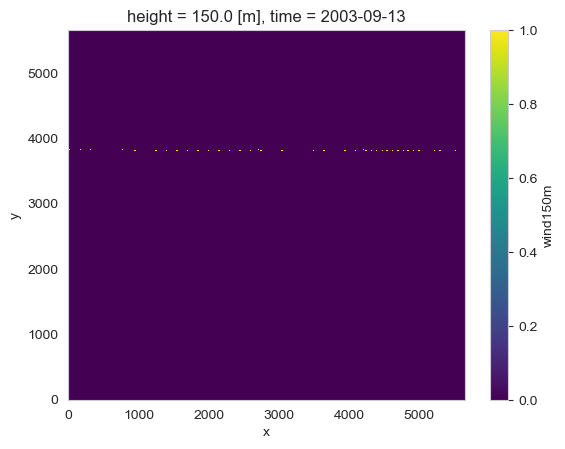

In [ ]:
ds.sel(time="2003-09-13 00:00").wind150m.isnull().plot()

In [8]:
height = 150
path_data_personal_cordex = Path(paths["path_data_personal"]) / "cordex" / "EUR-11"
u_path = sorted(
    list(
        (path_data_personal_cordex / institute / gcm / "historical").rglob(
            f"*/ua{height}m"
        )
    )[0].glob("*/*.nc")
)
v_path = sorted(
    list(
        (path_data_personal_cordex / institute / gcm / "historical").rglob(
            f"*/va{height}m"
        )
    )[0].glob("*/*.nc")
)

In [45]:
ds_u = xr.open_dataset(u_path[-3])
ds_u[f"ua{height}m"].where(ds_u[f"ua{height}m"] > 300, drop=True)["time"]

<xarray.DataArray 'time' (time: 1)> Size: 8B
array(['2003-09-13T00:00:00.000000000'], dtype='datetime64[ns]')
Coordinates:
    height   float64 8B 150.0
  * time     (time) datetime64[ns] 8B 2003-09-13
Attributes:
    axis:           T
    standard_name:  time
    long_name:      Time axis
    time_origin:    1949-12-01 00:00:00

In [ ]:
ds_u = xr.open_dataset(u_path[-3])
ds_u[f"ua{height}m"] = (
    ds_u[f"ua{height}m"].where(ds_u[f"ua{height}m"] < 300).ffill("time").bfill("time")
)
ds_v = xr.open_dataset(v_path[-3])
ds_v[f"va{height}m"] = (
    ds_v[f"va{height}m"].where(ds_v[f"va{height}m"] < 300).ffill("time").bfill("time")
)

In [47]:
max_value = ds_u[f"ua{height}m"].max()
time_of_max = ds_u.where(ds_u[f"ua{height}m"] == max_value, drop=True)["time"]

print(f"Max Value: {max_value.values}")
print(f"Time of Max: {time_of_max.values}")

Max Value: 44.680763244628906
Time of Max: ['2003-12-30T06:00:00.000000000']


In [48]:
max_value = ds_v[f"va{height}m"].max()
time_of_max = ds_v.where(ds_v[f"va{height}m"] == max_value, drop=True)["time"]

print(f"Max Value: {max_value.values}")
print(f"Time of Max: {time_of_max.values}")

Max Value: 47.75191116333008
Time of Max: ['2003-02-09T09:00:00.000000000']


In [ ]:
np.sqrt()

In [49]:
ds_wind = ds_u.copy().drop_vars(f"ua{height}m")
ds_wind[f"wind{height}m"] = convert_wind_components_to_speed(
    ds_u[f"ua{height}m"], ds_v[f"va{height}m"]
)
ds_wind[f"wind{height}m"].attrs.update(ds_u[f"ua{height}m"].attrs)
ds_wind[f"wind{height}m"].attrs.update(
    {
        "long_name": "Wind speed",
        "standard_name": "wind_speed",
        "units": "m s-1",
        "height": f"{height}m",
    }
)

/home/yhaddad/ClimateScenarios4Energy-CH/notebooks/processing/../../src/data_processing/convert_climate_vars.py:23: RuntimeWarning: overflow encountered in square
  lambda x, y: np.sqrt(x**2 + y**2),


# Load data

In [14]:
extent = {"lat_min": 30, "lat_max": 75, "lon_min": -12, "lon_max": 30}

ds_wind_150m = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "regridded"
    / "3hr"
    / "wind150m.zarr",
    extent=extent,
)

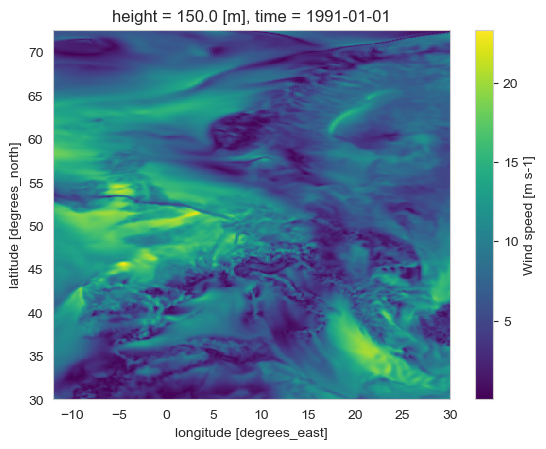

In [15]:
ds_wind_150m.ds_data.isel(time=0).wind150m.plot()

In [7]:
nan_values = ds_wind_100m.ds_data.sel(time=ds_wind_100m.ds_data.time.dt.hour == 0).isnull()
nan_values

<xarray.Dataset> Size: 7GB
Dimensions:   (time: 39785, lat: 426, lon: 420)
Coordinates:
    height    float64 8B ...
  * lat       (lat) float64 3kB 30.05 30.15 30.25 30.35 ... 72.35 72.45 72.55
  * lon       (lon) float64 3kB -11.95 -11.85 -11.75 ... 29.75 29.85 29.95
  * time      (time) datetime64[ns] 318kB 1991-01-01 1991-01-02 ... 2099-12-31
Data variables:
    wind100m  (time, lat, lon) bool 7GB True True True True ... True True True

In [10]:
cordex_wind_100m, cordex_wind_hist_100m = get_raw_cordex_data_paths(
    Path(paths["path_data_personal"]) / "cordex" / "EUR-11",
    climate_model_chain,
    climate_scenario,
    "wind100m",
    "3hr",
)

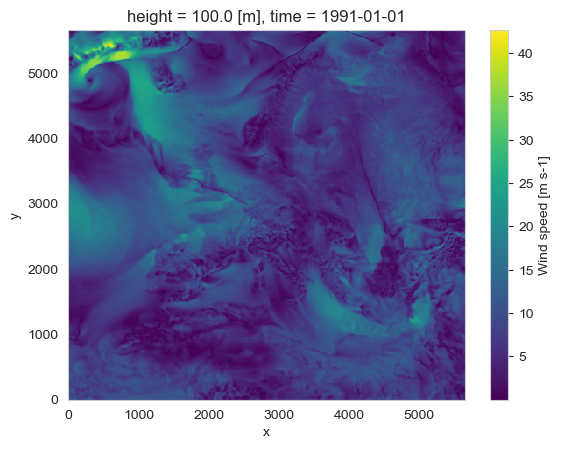

In [15]:
xr.open_dataset(sorted(cordex_wind_hist_100m.glob("*1991*"))[0]).wind100m.isel(time=-1).plot()